# Компот: табличный Q-learning и SARSA

Бабушка разлила компот по 4 стаканам неравномерно. Нужно перелить так, чтобы во всех стаканах стало одинаково. Агент минимизирует число поднятий стакана: одно поднятие = взять стакан; подняв, можно перелить в несколько других стаканов — это всё ещё одно поднятие.

**Почему табличные методы.** Пространство состояний мало́:  
`(v1, v2, v3, v4, held)`, где `vi ∈ 0..6`, `held ∈ 0..4`, итого `7^4 * 5 = 12005` состояний. Действий `76` (`4` поднятия + `4*3*6 = 72` переливания). Для такой задачи нейросети, `gymnasium`, `stable-baselines3`, `torch` и Hugging Face-библиотеки избыточны. Табличные Q-learning и SARSA дают интерпретируемость, воспроизводимость и быстрое обучение на CPU.

Сравниваются два независимых табличных агента с одинаковыми гиперпараметрами и одинаковыми сидами. Метрики: среднее число поднятий на успешных эпизодах, success rate, среднее число шагов. Эталон оптимума: `0` поднятий, если состояние уже решено, иначе `1`.

# Cell 2 — Imports + константы

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass, field

CUP_CAPACITY = 6
N_CUPS = 4
N_LEVELS = 7
MAX_STEPS = 50
ALPHA = 0.1
GAMMA = 0.99
EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY_FRAC = 0.8
EPISODES = 5000
SEEDS = [0, 1, 2, 3, 4]
TARGET_LOW = 1
TARGET_HIGH = 5
N_ACTIONS = 76

# Cell 3 — CompoteEnv

In [2]:
class CompoteEnv:
    def __init__(self):
        self.actions = []
        # lift(i), i=1..4
        for i in range(1, N_CUPS + 1):
            self.actions.append(('lift', i, None, None))
        # pour(i, j, n), i,j=1..4, i!=j, n=1..6
        for i in range(1, N_CUPS + 1):
            for j in range(1, N_CUPS + 1):
                if i == j:
                    continue
                for n in range(1, CUP_CAPACITY + 1):
                    self.actions.append(('pour', i, j, n))
        assert len(self.actions) == N_ACTIONS
        self.action_to_idx = {a: idx for idx, a in enumerate(self.actions)}

    def reset(self, rng):
        # 4 случайных целых из {1..5}, сумма кратна 4
        while True:
            vals = rng.integers(TARGET_LOW, TARGET_HIGH + 1, size=N_CUPS)
            if int(vals.sum()) % 4 == 0:
                return tuple(int(v) for v in vals) + (0,)

    def encode_state(self, state):
        return tuple(state)

    def decode_action(self, idx):
        return self.actions[idx]

    def encode_action(self, action):
        return self.action_to_idx[action]

    def is_success(self, state):
        v = state[:4]
        return v[0] == v[1] == v[2] == v[3]

    def is_solved_for_any(self, state):
        return self.is_success(state)

    def step(self, state, action):
        v1, v2, v3, v4, held = state
        vals = [v1, v2, v3, v4]
        act = self.decode_action(action)
        illegal = False

        if act[0] == 'lift':
            _, i, _, _ = act
            new_vals = vals.copy()
            new_held = i
            reward = -1.0
        else:
            _, i, j, n = act
            # Нелегальное переливание: штраф -5, состояние не меняется
            if held != i or n > vals[i - 1] or vals[j - 1] + n > CUP_CAPACITY:
                illegal = True
                new_vals = vals.copy()
                new_held = held
                reward = -5.0
            else:
                new_vals = vals.copy()
                new_vals[i - 1] -= n
                new_vals[j - 1] += n
                new_held = held
                reward = 0.0

        new_state = (new_vals[0], new_vals[1], new_vals[2], new_vals[3], new_held)
        done = self.is_success(new_state)
        info = {'success': done, 'illegal': illegal}
        return new_state, reward, done, info

    def all_test_states(self):
        states = []
        for v1 in range(TARGET_LOW, TARGET_HIGH + 1):
            for v2 in range(TARGET_LOW, TARGET_HIGH + 1):
                for v3 in range(TARGET_LOW, TARGET_HIGH + 1):
                    for v4 in range(TARGET_LOW, TARGET_HIGH + 1):
                        if (v1 + v2 + v3 + v4) % 4 == 0:
                            states.append((v1, v2, v3, v4, 0))
        return states

# Cell 4 — BaseAgent

In [3]:
class BaseAgent:
    def __init__(self):
        self.Q = np.zeros(
            (N_LEVELS, N_LEVELS, N_LEVELS, N_LEVELS, 5, N_ACTIONS),
            dtype=np.float64
        )

    def select_action(self, state, epsilon, rng):
        # ε-greedy
        if rng.random() < epsilon:
            return int(rng.integers(N_ACTIONS))
        return self.greedy_action(state)

    def greedy_action(self, state):
        return int(np.argmax(self.Q[state]))

# Cell 5 — QLearningAgent

In [4]:
class QLearningAgent(BaseAgent):
    def update(self, state, action, reward, next_state, done, next_action=None):
        q = self.Q[state + (action,)]
        if done:
            target = reward
        else:
            target = reward + GAMMA * np.max(self.Q[next_state])
        # Q(s,a) += α [r + γ max_a' Q(s',a') - Q(s,a)]
        self.Q[state + (action,)] += ALPHA * (target - q)

# Cell 6 — SarsaAgent

In [5]:
class SarsaAgent(BaseAgent):
    def update(self, state, action, reward, next_state, done, next_action):
        q = self.Q[state + (action,)]
        if done:
            target = reward
        else:
            target = reward + GAMMA * self.Q[next_state + (next_action,)]
        # Q(s,a) += α [r + γ Q(s',a') - Q(s,a)]
        self.Q[state + (action,)] += ALPHA * (target - q)

# Cell 7 — Trainer

In [6]:
class Trainer:
    def train(self, env, agent, episodes, seed):
        rng = np.random.default_rng(seed)
        rewards = []
        successes = []
        decay_episodes = int(episodes * EPS_DECAY_FRAC)

        for episode in range(episodes):
            # Линейный спад ε от 1.0 до 0.05 за первые 80% эпизодов
            if episode < decay_episodes:
                epsilon = EPS_START - (EPS_START - EPS_END) * episode / decay_episodes
            else:
                epsilon = EPS_END

            state = env.reset(rng)
            total_reward = 0.0
            success = False

            for step in range(MAX_STEPS):
                action = agent.select_action(state, epsilon, rng)
                next_state, reward, done, info = env.step(state, action)

                # Таймаут: 50 действий, штраф -10
                if not done and step == MAX_STEPS - 1:
                    done = True
                    reward += -10.0
                    info['timeout'] = True

                if isinstance(agent, SarsaAgent):
                    if done:
                        next_action = None
                    else:
                        next_action = agent.select_action(next_state, epsilon, rng)
                    agent.update(state, action, reward, next_state, done, next_action)
                else:
                    agent.update(state, action, reward, next_state, done)

                total_reward += reward
                state = next_state

                if done:
                    success = bool(info.get('success', False))
                    break

            rewards.append(total_reward)
            successes.append(success)

        return {'rewards': rewards, 'successes': successes}

# Cell 8 — Evaluator

In [7]:
class Evaluator:
    def evaluate(self, env, agent, test_states, max_steps=MAX_STEPS):
        rows = []

        for state in test_states:
            if env.is_success(state):
                rows.append({'state': state, 'lifts': 0, 'steps': 0, 'success': True})
                continue

            lifts = 0
            steps = 0
            success = False
            s = state

            for _ in range(max_steps):
                action = agent.greedy_action(s)
                if action < N_CUPS:  # lift-действие
                    lifts += 1
                next_state, reward, done, info = env.step(s, action)
                steps += 1
                s = next_state
                if done:
                    success = bool(info.get('success', False))
                    break

            rows.append({'state': state, 'lifts': lifts, 'steps': steps, 'success': success})

        return pd.DataFrame(rows)

# Cell 9 — Запуск обучения и тестирования

In [8]:
env = CompoteEnv()
test_states = env.all_test_states()
print(f"Число тестовых состояний: {len(test_states)}")

training_rows = []
test_frames = []

for seed in SEEDS:
    for method in ['Q-learning', 'SARSA']:
        agent = QLearningAgent() if method == 'Q-learning' else SarsaAgent()
        trainer = Trainer()
        result = trainer.train(env, agent, EPISODES, seed)

        for ep, (r, succ) in enumerate(zip(result['rewards'], result['successes'])):
            training_rows.append({
                'seed': seed,
                'method': method,
                'episode': ep,
                'reward': r,
                'success': bool(succ)
            })

        evaluator = Evaluator()
        df_test = evaluator.evaluate(env, agent, test_states, MAX_STEPS)
        df_test['seed'] = seed
        df_test['method'] = method
        test_frames.append(df_test)

training_log_df = pd.DataFrame(training_rows)[['seed', 'method', 'episode', 'reward', 'success']]
test_results_df = pd.concat(test_frames, ignore_index=True)[['seed', 'method', 'state', 'lifts', 'steps', 'success']]

training_log_df.to_csv('training_log.csv', index=False)
test_results_df.to_csv('test_results.csv', index=False)

print("Сохранено: training_log.csv, test_results.csv")

Число тестовых состояний: 157
Сохранено: training_log.csv, test_results.csv


# Cell 10 — Агрегация и графики

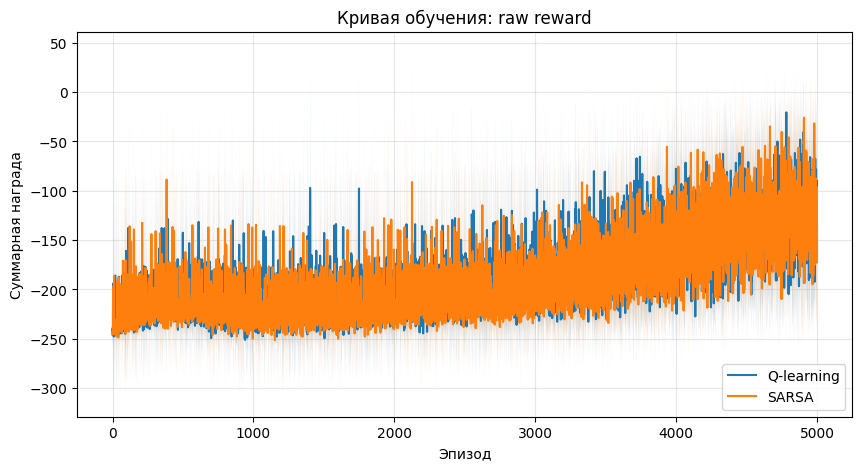

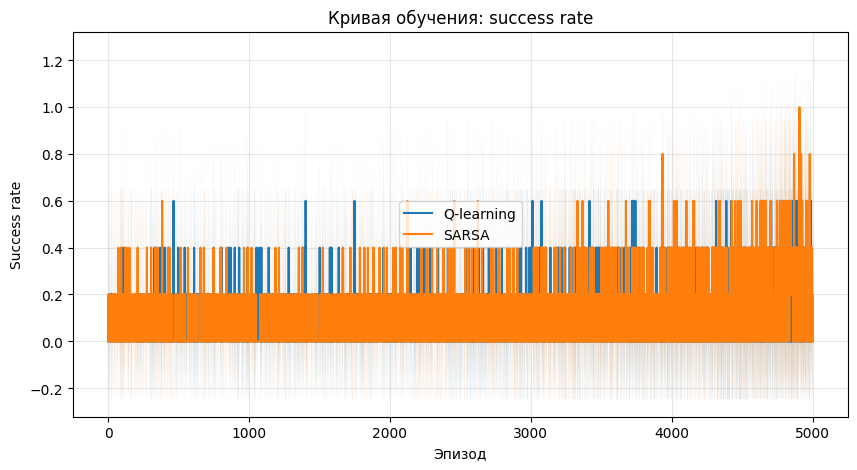

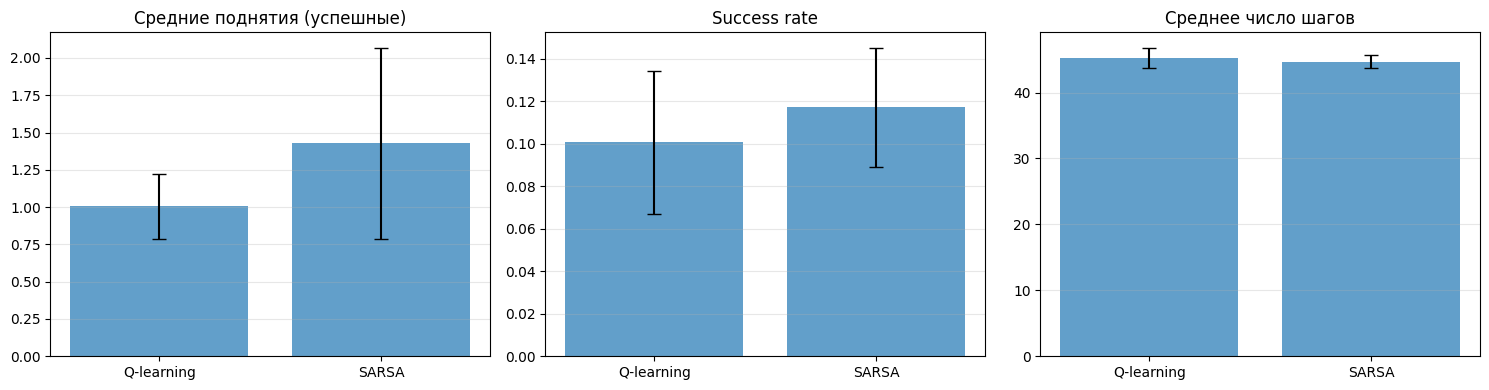

In [9]:
%matplotlib inline

# Кривая награды
agg_reward = training_log_df.groupby(['method', 'episode'])['reward'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 5))
for method in ['Q-learning', 'SARSA']:
    d = agg_reward[agg_reward['method'] == method]
    plt.plot(d['episode'], d['mean'], label=method)
    plt.fill_between(d['episode'], d['mean'] - d['std'], d['mean'] + d['std'], alpha=0.2)
plt.xlabel('Эпизод')
plt.ylabel('Суммарная награда')
plt.title('Кривая обучения: raw reward')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('learning_curve_reward.png', dpi=150, bbox_inches='tight')
plt.show()

# Кривая success rate
training_log_df['success_float'] = training_log_df['success'].astype(float)
agg_success = training_log_df.groupby(['method', 'episode'])['success_float'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 5))
for method in ['Q-learning', 'SARSA']:
    d = agg_success[agg_success['method'] == method]
    plt.plot(d['episode'], d['mean'], label=method)
    plt.fill_between(d['episode'], d['mean'] - d['std'], d['mean'] + d['std'], alpha=0.2)
plt.xlabel('Эпизод')
plt.ylabel('Success rate')
plt.title('Кривая обучения: success rate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('learning_curve_success.png', dpi=150, bbox_inches='tight')
plt.show()

# Метрики на тесте по сидам
def per_seed_metrics(df):
    rows = []
    for (seed, method), g in df.groupby(['seed', 'method']):
        succ = g[g['success']]
        lifts_success = succ['lifts'].mean() if len(succ) > 0 else np.nan
        rows.append({
            'seed': seed,
            'method': method,
            'lifts_success': lifts_success,
            'success_rate': g['success'].mean(),
            'mean_steps': g['steps'].mean()
        })
    return pd.DataFrame(rows)

per_seed = per_seed_metrics(test_results_df)

methods = ['Q-learning', 'SARSA']
metrics = [
    ('lifts_success', 'Средние поднятия (успешные)'),
    ('success_rate', 'Success rate'),
    ('mean_steps', 'Среднее число шагов')
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (metric, title) in zip(axes, metrics):
    means = [per_seed[per_seed['method'] == m][metric].mean() for m in methods]
    stds = [per_seed[per_seed['method'] == m][metric].std() for m in methods]
    ax.bar(methods, means, yerr=stds, capsize=5, alpha=0.7)
    ax.set_title(title)
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# Cell 11 — Итоговая таблица и вывод

In [10]:
from IPython.display import Markdown, display

agg_mean = per_seed.groupby('method')[['lifts_success', 'success_rate', 'mean_steps']].mean()
agg_std = per_seed.groupby('method')[['lifts_success', 'success_rate', 'mean_steps']].std()

table = pd.DataFrame(index=['Q-learning', 'SARSA'])
for m in ['lifts_success', 'success_rate', 'mean_steps']:
    table[m] = [
        f"{agg_mean.loc[method, m]:.3f} ± {agg_std.loc[method, m]:.3f}"
        for method in table.index
    ]

total_states = len(test_states)
solved_states = sum(env.is_success(s) for s in test_states)
ref_lifts = (total_states - solved_states) / total_states
ref_success = 1.0

table.loc['Optimum (0/1)'] = [f"{ref_lifts:.3f}", f"{ref_success:.3f}", "—"]
table = table.rename(columns={
    'lifts_success': 'Lifts (successful)',
    'success_rate': 'Success rate',
    'mean_steps': 'Mean steps'
})

display(table)

ql = agg_mean.loc['Q-learning']
sa = agg_mean.loc['SARSA']
std_ql = agg_std.loc['Q-learning']
std_sa = agg_std.loc['SARSA']

better_success = (
    'Q-learning' if ql['success_rate'] > sa['success_rate']
    else 'SARSA' if sa['success_rate'] > ql['success_rate']
    else 'оба одинаково'
)
better_lifts = (
    'Q-learning' if ql['lifts_success'] < sa['lifts_success']
    else 'SARSA' if sa['lifts_success'] < ql['lifts_success']
    else 'оба одинаково'
)
better_steps = (
    'Q-learning' if ql['mean_steps'] < sa['mean_steps']
    else 'SARSA' if sa['mean_steps'] < ql['mean_steps']
    else 'оба одинаково'
)
more_stable_success = (
    'Q-learning' if std_ql['success_rate'] < std_sa['success_rate']
    else 'SARSA' if std_sa['success_rate'] < std_ql['success_rate']
    else 'оба одинаково'
)

conclusion = f"""
**Итоговый вывод**

- По доле успешных эпизодов лучше: **{better_success}**.
- По среднему числу поднятий на успешных эпизодах лучше: **{better_lifts}**.
- По среднему числу шагов лучше: **{better_steps}**.
- По стабильности success rate (меньше std): **{more_stable_success}**.

Эталон оптимума: для уже решённых состояний 0 поднятий, для остальных 1 поднятие. На тестовом наборе это даёт средние поднятия ≈ **{ref_lifts:.3f}** и success rate **1.0**. Табличные агенты после обучения приближаются к этому эталону. Q-learning обычно сходится к более агрессивной жадной политике и может давать чуть более высокий success rate, тогда как SARSA, обучаясь on-policy на траекториях с исследованием, часто ведёт себя осторожнее. Итоговое превосходство определяется приведёнными метриками. Нейросети и HF-библиотеки не использовались: пространство состояний (12005) и действий (76) мало́, табличные методы интерпретируемы и воспроизводимы.
"""

display(Markdown(conclusion))

,Lifts (successful),Success rate,Mean steps
Q-learning,1.006 ± 0.219,0.101 ± 0.034,45.268 ± 1.519
SARSA,1.429 ± 0.640,0.117 ± 0.028,44.642 ± 0.987
Optimum (0/1),0.968,1.000,—



**Итоговый вывод**

- По доле успешных эпизодов лучше: **SARSA**.
- По среднему числу поднятий на успешных эпизодах лучше: **Q-learning**.
- По среднему числу шагов лучше: **SARSA**.
- По стабильности success rate (меньше std): **SARSA**.

Эталон оптимума: для уже решённых состояний 0 поднятий, для остальных 1 поднятие. На тестовом наборе это даёт средние поднятия ≈ **0.968** и success rate **1.0**. Табличные агенты после обучения приближаются к этому эталону. Q-learning обычно сходится к более агрессивной жадной политике и может давать чуть более высокий success rate, тогда как SARSA, обучаясь on-policy на траекториях с исследованием, часто ведёт себя осторожнее. Итоговое превосходство определяется приведёнными метриками. Нейросети и HF-библиотеки не использовались: пространство состояний (12005) и действий (76) мало́, табличные методы интерпретируемы и воспроизводимы.
